In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

import sys
module_path = os.path.abspath(os.path.join('..', '..', '..', 'build')) 
if module_path not in sys.path:
    sys.path.append(module_path)
    
from utilities import mem_usage, make_folder

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 500)

### Prep files

In [2]:
# filepaths 
FP_SUBZONE_SHP2014 = os.path.join('zip://', '..',  '..', '..', 'raw-files', 'master-plan-2014-subzone-boundary-no-sea', 'master-plan-2014-subzone-boundary-no-sea-shp.zip')
FP_ZONE_SHP2014 = os.path.join('zip://', '..', '..', '..', 'raw-files', 'master-plan-2014-planning-area-boundary-no-sea', 'master-plan-2014-planning-area-boundary-no-sea-shp.zip')
FP_REGION_SHP2014_ = os.path.join('zip://', '..','..', '..',  'raw-files', 'master-plan-2014-region-boundary-no-sea', 'master-plan-2014-region-boundary-no-sea-shp.zip')

FP_CITYDATA_SUBZONES = os.path.join('..','..', '..', 'build', 'intermediate-files', 'citydata-subzones.csv')
FP_MOVEMENT = os.path.join('..','..', '..', 'build', 'intermediate-files', 'daily-movecount.csv.gz')
FP_HTYPE = os.path.join('..','..', '..', 'build', 'intermediate-files', 'htype.csv')
SAVEPATH = os.path.join('..', '..', '..', 'ms', 'figures', 'conn-maps')

make_folder(SAVEPATH)

..\..\..\ms\figures\conn-maps already exists.


In [3]:
# Clean obvious name errors from Citydata (to get perfect match)
clean_cd_subzone = {'marina east mp': 'marina east (mp)', 
                    'monks hill': "monk's hill", 
                    "national university of s pore": "national university of s'pore", 
                    "peoples park": "people's park"}

In [4]:
# Read in URA2014 version
subzones2014 = (gpd.read_file(FP_SUBZONE_SHP2014)
                .rename(columns={'SUBZONE_N': 'subzone'})
                .assign(subzone=lambda df: df['subzone'].str.lower())
                .assign(centroid=lambda df: df['geometry'].centroid)
               )

zones2014 = gpd.read_file(FP_ZONE_SHP2014)

regions2014 = gpd.read_file(FP_REGION_SHP2014_)

In [5]:
# Read in citydata subzones
cd_subzones = (pd.read_csv(FP_CITYDATA_SUBZONES)
               .assign(subzone=lambda df: df['subzone'].str.lower())
               .assign(subzone=lambda df: df['subzone'].replace(clean_cd_subzone))
              )

# Merge with URA shp
cd_subzones = cd_subzones.merge(subzones2014[['subzone', 'geometry']], 
                                how='left', on='subzone', indicator=True)

assert len(cd_subzones[cd_subzones['_merge']=='left_only'])==0

subzones_dict = dict(zip(cd_subzones['areaid'], cd_subzones['subzone']))

cd_subzones.head(3)

,subzone,areaid,geometry,_merge
0,admiralty,0,"POLYGON ((27468.829 48929.475, 27487.489 48902...",both
1,airport road,1,"POLYGON ((35580.279 37584.162, 35553.987 37534...",both
2,alexandra hill,2,"POLYGON ((25899.699 29766.744, 25886.223 29714...",both


In [6]:
# Read in movement matrix for weekdays and map area xid back to citydata subzone name
move = (pd.read_csv(FP_MOVEMENT, compression='gzip')
        .assign(date=lambda df: df['date']+100000)
        .assign(date=lambda df: pd.to_datetime(df['date'],unit='s'))
        .assign(dow=lambda df: [ts.isoweekday() for ts in df['date']])
#         .query('dow<6')
#         #         .drop('date', axis=1)
        .groupby(['home', 'area_id']).sum().reset_index()
        .assign(source=lambda df: df['home'].map(subzones_dict))
        .assign(dest=lambda df: df['area_id'].map(subzones_dict)) 
        .assign(source=lambda df: df['source'].str.lower())  
        .assign(dest=lambda df: df['dest'].str.lower())  
        .assign(source=lambda df: df['source'].replace(clean_cd_subzone))
        .assign(dest=lambda df: df['dest'].replace(clean_cd_subzone))
       )

# Merge with URA shp
move = (move.merge(subzones2014[['subzone', 'centroid']], how='left', left_on='source', right_on='subzone')
        .assign(slong=lambda df: [pt.coords[0][0] for pt in df['centroid']])
        .assign(slat=lambda df: [pt.coords[0][1] for pt in df['centroid']])
        .drop('centroid', axis=1)
       )

move = (move.merge(subzones2014[['subzone', 'centroid']], how='left', left_on='dest', right_on='subzone')
        .assign(dlong=lambda df: [pt.coords[0][0] for pt in df['centroid']])
        .assign(dlat=lambda df: [pt.coords[0][1] for pt in df['centroid']])
       )

# Get total home for percentages
move = move.merge(move.groupby(['home'])['inflow_count'].sum().reset_index()
                  .rename(columns={'inflow_count': 'tt'}), 
                  how='left', on=['home'], validate='m:1'
                 )
move['flow'] = move['inflow_count'] / move['tt'] * 100

move.drop(['subzone_x', 'subzone_y', 'centroid', 'home', 'area_id'], axis=1, inplace=True)

move.head(3)

,inflow_count,dow,source,dest,slong,slat,dlong,dlat,tt,flow
0,813,364,admiralty,admiralty,27091.275536,48333.800595,27091.275536,48333.800595,2890,28.131488
1,1,1,admiralty,airport road,27091.275536,48333.800595,35133.315461,37075.318444,2890,0.034602
2,1,1,admiralty,alexandra hill,27091.275536,48333.800595,25358.820869,29991.384228,2890,0.034602


In [7]:
# Read in Htypes
htype = (pd.read_csv(FP_HTYPE, usecols=['area', 'resident_count', 'rm12', 'private'])
         .rename(columns={'area': 'subzone'})
         .assign(resident_count=lambda df: df['resident_count'].replace(0, np.nan))
        )

htype = subzones2014[['subzone', 'geometry', 'PLN_AREA_N', 'REGION_C']].merge(htype, how='left', on='subzone', validate='1:1')
cr = htype[htype['REGION_C']=='CR']

### Which areas?

In [8]:
htype[htype['subzone']=='lavender']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
100,lavender,"POLYGON ((31389.563 32098.173, 31371.719 32078...",KALLANG,CR,9180.0,32.897603,27.233115


In [9]:
htype[htype['rm12']==0].sort_values('resident_count', ascending=False)

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
227,hougang west,"POLYGON ((34621.730 40056.820, 34617.316 39688...",HOUGANG,NER,44990.0,0.000000,0.0
318,yew tee,"POLYGON ((18349.061 43028.676, 18383.850 43027...",CHOA CHU KANG,WR,40950.0,11.428571,0.0
150,simei,"POLYGON ((41221.164 34721.105, 41191.669 34697...",TAMPINES,ER,39890.0,40.762096,0.0
232,pasir ris west,"POLYGON ((40016.024 39464.455, 40007.149 39461...",PASIR RIS,ER,36110.0,22.348380,0.0
120,frankel,"POLYGON ((36551.527 31992.904, 36532.074 31986...",BEDOK,ER,33780.0,100.000000,0.0
251,lorong ah soo,"POLYGON ((34418.457 37253.285, 34371.441 37143...",HOUGANG,NER,32400.0,23.981481,0.0
225,jelebu,"POLYGON ((20458.985 39151.027, 20336.163 39051...",BUKIT PANJANG,WR,31660.0,22.710044,0.0
193,marymount,"POLYGON ((29469.703 36372.102, 29466.131 36348...",BISHAN,CR,29930.0,23.955897,0.0
146,bedok reservoir,"POLYGON ((39853.918 35309.137, 39812.609 35283...",BEDOK,ER,25610.0,30.925420,0.0
221,hougang east,"POLYGON ((35819.134 40203.025, 35821.006 40148...",HOUGANG,NER,25170.0,7.508939,0.0


In [10]:
a = htype[htype['rm12']>0].sort_values('rm12', ascending=False)
a[a['REGION_C']=='CR']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
11,pearl's hill,"POLYGON ((29092.275 30021.888, 29119.641 30006...",OUTRAM,CR,6340.0,6.624606,71.293375
50,crawford,"POLYGON ((31494.252 32088.463, 31586.770 31957...",KALLANG,CR,8840.0,6.674208,49.208145
56,sungei road,"POLYGON ((30371.777 31738.942, 30314.691 31718...",ROCHOR,CR,2010.0,0.000000,32.835821
238,boon teck,"POLYGON ((30184.865 34845.258, 30054.848 34826...",TOA PAYOH,CR,14030.0,0.000000,32.216679
13,henderson hill,"POLYGON ((27131.276 30059.727, 27088.334 29709...",BUKIT MERAH,CR,13380.0,1.420030,29.372197
15,alexandra hill,"POLYGON ((25899.699 29766.744, 25886.223 29714...",BUKIT MERAH,CR,13350.0,0.000000,29.288390
100,lavender,"POLYGON ((31389.563 32098.173, 31371.719 32078...",KALLANG,CR,9180.0,32.897603,27.233115
16,bukit ho swee,"POLYGON ((27746.952 30497.168, 27758.001 30496...",BUKIT MERAH,CR,14750.0,3.661017,25.084746
60,commonwealth,"POLYGON ((24544.101 32168.623, 24503.180 32062...",QUEENSTOWN,CR,7210.0,0.000000,23.162275
24,kampong tiong bahru,"POLYGON ((26931.602 29369.877, 27351.033 29162...",BUKIT MERAH,CR,9160.0,0.000000,22.489083


In [11]:
htype[htype['subzone']=='crawford']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
50,crawford,"POLYGON ((31494.252 32088.463, 31586.770 31957...",KALLANG,CR,8840.0,6.674208,49.208145


In [12]:
htype[htype['subzone']=='tanjong rhu']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
58,tanjong rhu,"POLYGON ((31632.977 30741.729, 31561.689 30728...",KALLANG,CR,10950.0,66.666667,4.383562


In [13]:
htype[htype['subzone']=='hillcrest']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
243,hillcrest,"POLYGON ((25392.543 35958.770, 25389.434 35896...",BUKIT TIMAH,CR,9010.0,100.0,0.0


In [14]:
htype[htype['subzone']=='katong']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
92,katong,"POLYGON ((36317.742 32458.455, 36335.320 32380...",MARINE PARADE,CR,9160.0,100.0,0.0


In [15]:
cr['rm12'] = np.log(1+cr['rm12'])

D:\ProgramData\Anaconda3\lib\site-packages\geopandas\geodataframe.py:853: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super(GeoDataFrame, self).__setitem__(key, value)


In [16]:
cr[cr['subzone']=='katong']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
92,katong,"POLYGON ((36317.742 32458.455, 36335.320 32380...",MARINE PARADE,CR,9160.0,100.0,0.0


In [17]:
cr[cr['subzone']=='tanjong rhu']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
58,tanjong rhu,"POLYGON ((31632.977 30741.729, 31561.689 30728...",KALLANG,CR,10950.0,66.666667,1.68335


In [18]:
htype[htype['subzone']=='nicoll']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12


In [19]:
cr.sort_values(['rm12', 'private', 'resident_count'], ascending=[True, False, False])

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
108,ulu pandan,"POLYGON ((23068.305 33143.086, 23137.916 33077...",BUKIT TIMAH,CR,10890.0,100.000000,0.000000
175,holland road,"POLYGON ((23191.904 33716.074, 23159.098 33668...",BUKIT TIMAH,CR,10680.0,100.000000,0.000000
59,mountbatten,"POLYGON ((34842.598 30937.355, 34736.949 30903...",MARINE PARADE,CR,10160.0,100.000000,0.000000
111,nassim,"POLYGON ((26819.044 31934.557, 26817.779 31933...",TANGLIN,CR,9650.0,100.000000,0.000000
92,katong,"POLYGON ((36317.742 32458.455, 36335.320 32380...",MARINE PARADE,CR,9160.0,100.000000,0.000000
243,hillcrest,"POLYGON ((25392.543 35958.770, 25389.434 35896...",BUKIT TIMAH,CR,9010.0,100.000000,0.000000
78,chatsworth,"POLYGON ((27519.617 31260.508, 27535.089 31260...",TANGLIN,CR,6710.0,100.000000,0.000000
133,leedon park,"POLYGON ((23704.381 33935.752, 23907.751 33766...",BUKIT TIMAH,CR,6420.0,100.000000,0.000000
90,coronation road,"POLYGON ((25771.955 33918.047, 25759.207 33852...",BUKIT TIMAH,CR,6290.0,100.000000,0.000000
177,sennett,"POLYGON ((32843.211 35529.812, 32940.611 35443...",TOA PAYOH,CR,5300.0,100.000000,0.000000


### Plot connection maps using house type

In [20]:
move.describe(percentiles=[.01, .05, .1])

,inflow_count,dow,slong,slat,dlong,dlat,tt,flow
count,75390.000000,75390.000000,75390.000000,75390.000000,75390.000000,75390.000000,7.539000e+04,75390.000000
mean,190.386165,110.255631,27219.130190,35928.779917,27404.543462,35713.754083,5.524401e+04,0.393951
std,5001.495673,102.788642,7580.810750,4936.597203,7332.582436,4945.768032,1.561255e+05,2.715994
min,1.000000,1.000000,5092.894974,26137.873531,5092.894974,26137.873531,4.100000e+01,0.000155
1%,1.000000,2.000000,8872.750171,28501.664970,7798.167716,28466.778334,1.238000e+03,0.003183
5%,1.000000,5.000000,13953.527111,29131.036839,14079.100430,29096.753923,3.290000e+03,0.009029
10%,2.000000,7.000000,17651.309092,29893.781283,17912.977827,29776.433459,5.117000e+03,0.015114
50%,22.000000,75.000000,28465.399958,35114.906266,28542.648569,34982.196249,2.771800e+04,0.081021
max,710894.000000,364.000000,46661.849042,48346.032612,46661.849042,48346.032612,1.931543e+06,100.000000


In [21]:
# Drop zones/subzones to shrink map
# https://www.citypopulation.de/en/singapore/admin/

subzones_to_drop = ['north-eastern islands', 'sudong', 'semakau', 'jurong island and bukom', 'southern group',
                    'tuas bay', 'tuas north', 'tuas view', 'tuas view extension', 'tuas promenade', 
                    'changi airport', 'changi bay', 'tengeh', 'western water catchment', 'lim chu kang', 
                    'reservoir view', 'gul circle', 'pioneer sector', 'safti', 'joo koon', 
                    'gul basin', 'benoi sector', 'samulun', 
                    'senoko north', 'the wharves', 'kranji', 'pang sua', 
                    'tanjong irau', 'pulau seletar']
cr = cr[~cr['subzone'].isin(subzones_to_drop)]

zones_to_drop = ['SOUTHERN ISLANDS', 'NORTH-EASTERN ISLANDS', 'WESTERN ISLANDS']
zones2014 = zones2014[~zones2014['PLN_AREA_N'].isin(zones_to_drop)]

In [22]:
# Graph settings
FIGSIZE = (10, 10)

AREA_LINEWIDTH = 1.5
EDGE_COLOR = 'darkgray'

ZONE_LINEWIDTH=3
ZONE_EDGECOLOR = 'dimgray'

MOVE_COLOR = 'black'
MOVE_LINE_ALPHA = .99
MOVE_LWIDTH_NORM = 400

FLOW_CUTOFF = .8 # percentage (5th percentile)
# BASE_FLOW_CUTOFF = 50  # actual count ()

CM = 'Oranges'
MISSKWDS = {"color": "black", "edgecolor": "white", "hatch": "///", "label": "Missing values"}
DPI = 300

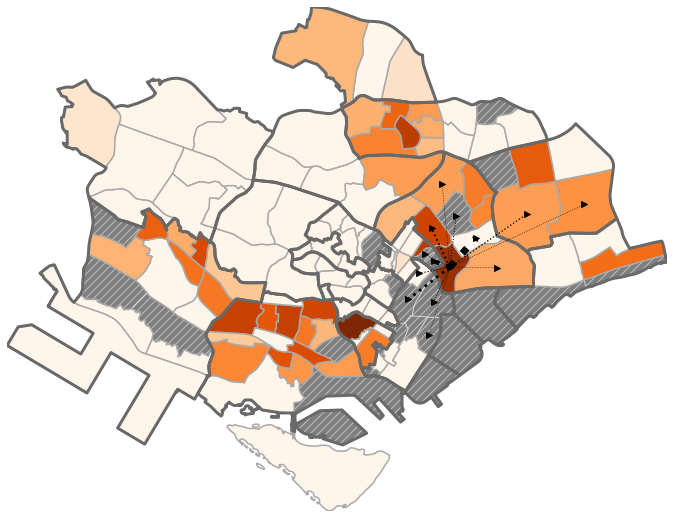

In [23]:
# Plot crawford
SELECTED_AREA = 'crawford'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

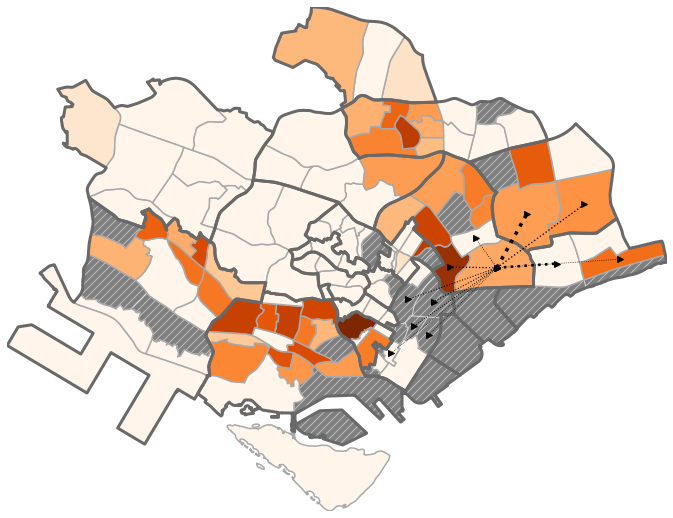

In [24]:
# Plot tanjong rhu
SELECTED_AREA = 'tanjong rhu'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

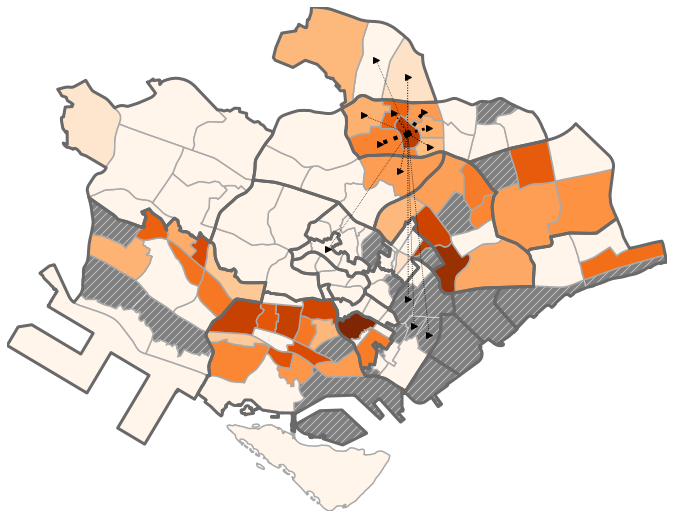

In [25]:
# Plot Boon Teck
SELECTED_AREA = 'boon teck'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

In [26]:
a = htype[htype['rm12']>0].sort_values('rm12', ascending=False)
a[a['REGION_C']=='CR']

,subzone,geometry,PLN_AREA_N,REGION_C,resident_count,private,rm12
11,pearl's hill,"POLYGON ((29092.275 30021.888, 29119.641 30006...",OUTRAM,CR,6340.0,6.624606,71.293375
50,crawford,"POLYGON ((31494.252 32088.463, 31586.770 31957...",KALLANG,CR,8840.0,6.674208,49.208145
56,sungei road,"POLYGON ((30371.777 31738.942, 30314.691 31718...",ROCHOR,CR,2010.0,0.000000,32.835821
238,boon teck,"POLYGON ((30184.865 34845.258, 30054.848 34826...",TOA PAYOH,CR,14030.0,0.000000,32.216679
13,henderson hill,"POLYGON ((27131.276 30059.727, 27088.334 29709...",BUKIT MERAH,CR,13380.0,1.420030,29.372197
15,alexandra hill,"POLYGON ((25899.699 29766.744, 25886.223 29714...",BUKIT MERAH,CR,13350.0,0.000000,29.288390
100,lavender,"POLYGON ((31389.563 32098.173, 31371.719 32078...",KALLANG,CR,9180.0,32.897603,27.233115
16,bukit ho swee,"POLYGON ((27746.952 30497.168, 27758.001 30496...",BUKIT MERAH,CR,14750.0,3.661017,25.084746
60,commonwealth,"POLYGON ((24544.101 32168.623, 24503.180 32062...",QUEENSTOWN,CR,7210.0,0.000000,23.162275
24,kampong tiong bahru,"POLYGON ((26931.602 29369.877, 27351.033 29162...",BUKIT MERAH,CR,9160.0,0.000000,22.489083


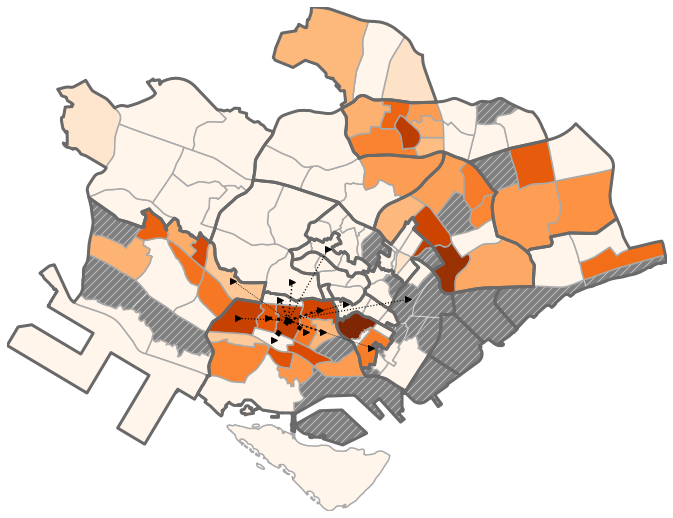

In [27]:
# Plot Henderson Hill
SELECTED_AREA = 'henderson hill'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

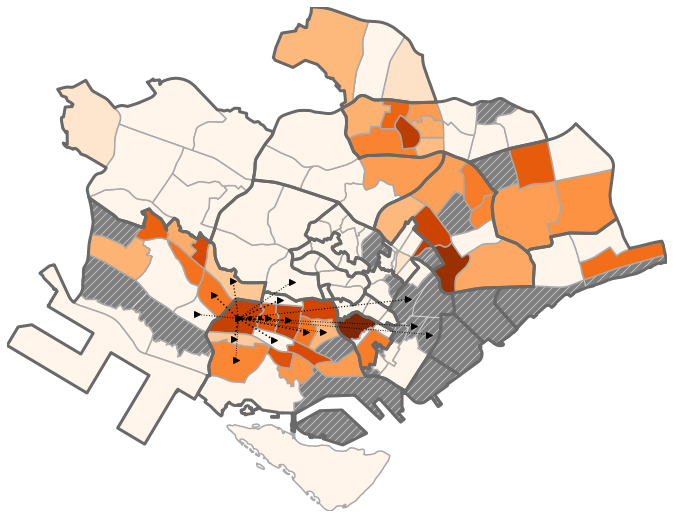

In [28]:
# Plot Alexandra Hill
SELECTED_AREA = 'alexandra hill'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

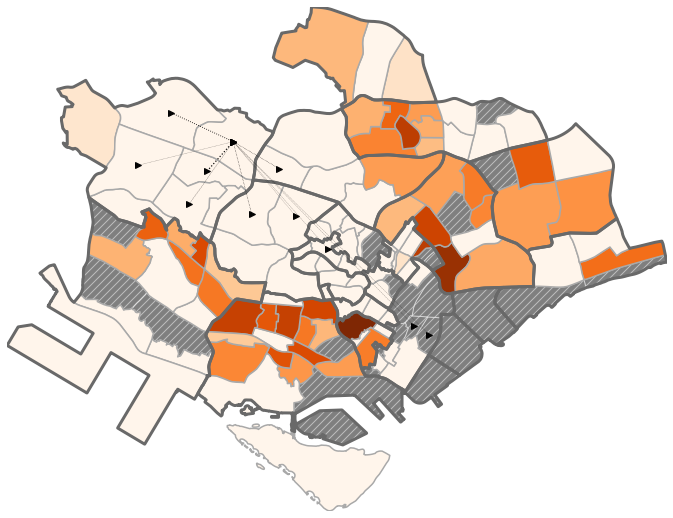

In [29]:
# Plot hillcrest
SELECTED_AREA = 'hillcrest'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

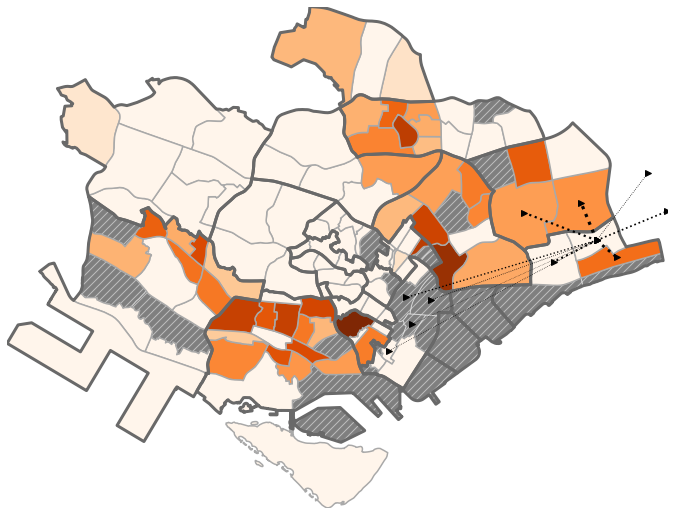

In [30]:
# Plot katong
SELECTED_AREA = 'katong'

fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
cr[cr['resident_count'].isnull()].plot(column='resident_count', alpha=.5,
                                       edgecolor=EDGE_COLOR,
                                       missing_kwds=MISSKWDS,
                                       ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
cr.plot(column='rm12', cmap=CM,
        edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
        ax=ax, zorder=2)

# Census area layer
zones2014[zones2014['REGION_C']=='CR'].plot(color='none', edgecolor=ZONE_EDGECOLOR, 
                                            linewidth=ZONE_LINEWIDTH,
                                            ax=ax, zorder=3)

# Plot movement lines
for slat,dlat, slon, dlon, area, flow, base in zip(move["slat"], move["dlat"], move["slong"], move["dlong"], 
                                             move['source'], move["flow"], move['inflow_count']):
    if area==SELECTED_AREA:
#         if (flow>FLOW_CUTOFF) & (base > BASE_FLOW_CUTOFF):
        if flow>FLOW_CUTOFF:
            plt.plot([slon , dlon], [slat, dlat], linewidth=base/MOVE_LWIDTH_NORM, color=MOVE_COLOR, alpha=MOVE_LINE_ALPHA, 
                     zorder=4, linestyle=':', marker='>')

plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)
plt.savefig(os.path.join(SAVEPATH, f'{SELECTED_AREA}.png'), dpi=DPI, bbox_inches='tight', pad_inches=0)

### Choropleth for house type

In [31]:
htype['centroid'] = htype['geometry'].centroid
htype['subzone'] = htype['subzone'].str.title()

In [32]:
AREA_ANNOTE_SIZE = 15

In [33]:
# Drop zones/subzones to shrink map
# https://www.citypopulation.de/en/singapore/admin/

subzones_to_drop = ['north-eastern islands', 'sudong', 'semakau', 'jurong island and bukom', 'southern group',
                    'tuas bay', 'tuas north', 'tuas view', 'tuas view extension', 'tuas promenade', 
                    'changi airport', 'changi bay', 'tengeh', 'western water catchment', 'lim chu kang', 
                    'reservoir view', 'gul circle', 'pioneer sector', 'safti', 'joo koon', 
                    'gul basin', 'benoi sector', 'samulun', 
                    'senoko north', 'the wharves', 'kranji', 'pang sua', 
                    'tanjong irau', 'pulau seletar']
cr = cr[~cr['subzone'].isin(subzones_to_drop)]

subzones_to_drop = ['North-Eastern Islands', 'Sudong', 'Semakau', 'Jurong Island And Bukom', 'Southern Group']
htype = htype[~htype['subzone'].isin(subzones_to_drop)]
htype = htype[htype['PLN_AREA_N']!='TUAS']

zones_to_drop = ['SOUTHERN ISLANDS', 'NORTH-EASTERN ISLANDS', 'WESTERN ISLANDS', 'TUAS']
zones2014 = zones2014[~zones2014['PLN_AREA_N'].isin(zones_to_drop)]

In [34]:
# Graph settings
FIGSIZE = (10, 10)

AREA_LINEWIDTH = .3
EDGE_COLOR = 'darkgray'

ZONE_LINEWIDTH=2
ZONE_EDGECOLOR = 'dimgray'

CM_POOR = 'Oranges'
CM_WEALTHY = 'Purples'
MISSKWDS = {"color": "dimgray", "edgecolor": "gainsboro", "hatch": "/////", "label": "Missing values"}
DPI = 300

SCHEME='quantiles'

D:\ProgramData\Anaconda3\lib\site-packages\mapclassify\classifiers.py:236: UserWarning: Warning: Not enough unique values in array to form k classes
  "Warning: Not enough unique values in array to form k classes", UserWarning
D:\ProgramData\Anaconda3\lib\site-packages\mapclassify\classifiers.py:238: UserWarning: Warning: setting k to 4
  Warn("Warning: setting k to %d" % k_q, UserWarning)


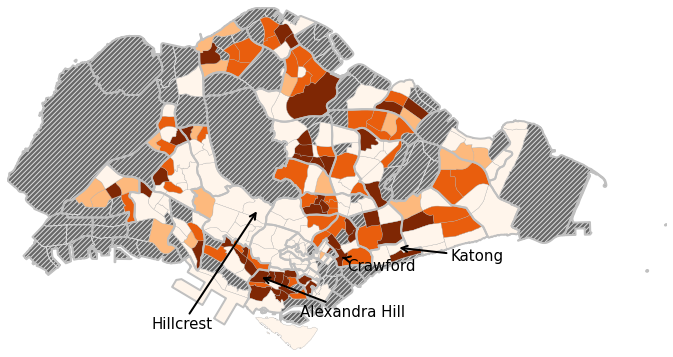

In [35]:
# Plot
fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
htype[htype['resident_count'].isnull()].plot(column='resident_count',
                                             edgecolor=EDGE_COLOR,
                                             missing_kwds=MISSKWDS,
                                             ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
htype.plot(column='rm12', cmap=CM_POOR,
           scheme=SCHEME,
           edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
           ax=ax, zorder=2)

# Census area layer
zones2014.plot(color='none', edgecolor='silver', 
               linewidth=ZONE_LINEWIDTH,
               ax=ax, zorder=3)

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Crawford':
        plt.annotate(area, xy=(lat, long), xytext=(lat+500, long-1000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Alexandra Hill':
        plt.annotate(area, xy=(lat, long), xytext=(lat+3000, long-3000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Hillcrest':
        plt.annotate(area, xy=(lat, long), xytext=(lat-8000, long-9000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)        

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Katong':
        plt.annotate(area, xy=(lat, long), xytext=(lat+4000, long-1000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)  
        
plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, 'rm12-choropleth.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)

D:\ProgramData\Anaconda3\lib\site-packages\mapclassify\classifiers.py:236: UserWarning: Warning: Not enough unique values in array to form k classes
  "Warning: Not enough unique values in array to form k classes", UserWarning
D:\ProgramData\Anaconda3\lib\site-packages\mapclassify\classifiers.py:238: UserWarning: Warning: setting k to 4
  Warn("Warning: setting k to %d" % k_q, UserWarning)


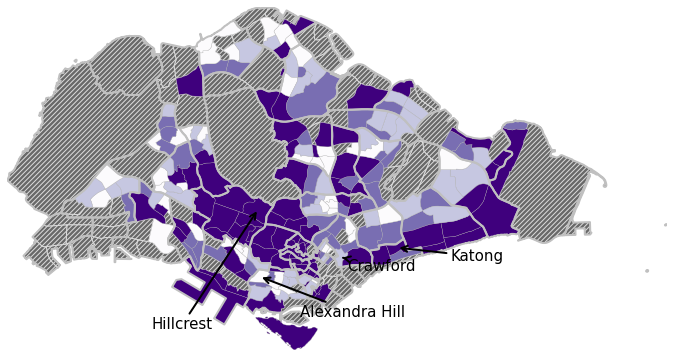

In [36]:
# Plot
fig, ax = plt.subplots(figsize=FIGSIZE)

# Subzones non-residential/missing areas
htype[htype['resident_count'].isnull()].plot(column='resident_count',
                                             edgecolor=EDGE_COLOR,
                                             missing_kwds=MISSKWDS,
                                             ax=ax, zorder=1)
# Subzones choropleth/non-missing areas
htype.plot(column='private', cmap=CM_WEALTHY,
           scheme=SCHEME,
           edgecolor=EDGE_COLOR, linewidth=AREA_LINEWIDTH,
           ax=ax, zorder=2)

# Census area layer
zones2014.plot(color='none', edgecolor='silver', 
               linewidth=ZONE_LINEWIDTH,
               ax=ax, zorder=3)

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Crawford':
        plt.annotate(area, xy=(lat, long), xytext=(lat+500, long-1000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Alexandra Hill':
        plt.annotate(area, xy=(lat, long), xytext=(lat+3000, long-3000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Hillcrest':
        plt.annotate(area, xy=(lat, long), xytext=(lat-8000, long-9000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)        

for area, lat, long in zip(htype['subzone'], htype['centroid'].x, htype['centroid'].y,):
    if area=='Katong':
        plt.annotate(area, xy=(lat, long), xytext=(lat+4000, long-1000), 
             arrowprops=dict(arrowstyle= '->', lw=2, color='black'), size=AREA_ANNOTE_SIZE)  
             
plt.tight_layout()
plt.margins(0,0)
plt.axis('off')

SELECTED_AREA = '-'.join(SELECTED_AREA.split(' '))
plt.savefig(os.path.join(SAVEPATH, 'private-choropleth.pdf'), dpi=DPI, bbox_inches='tight', pad_inches=0)